Image: India_000028.jpg
XML dimensions: 720 x 720
Class: D20, Box: (121, 527, 702, 712)


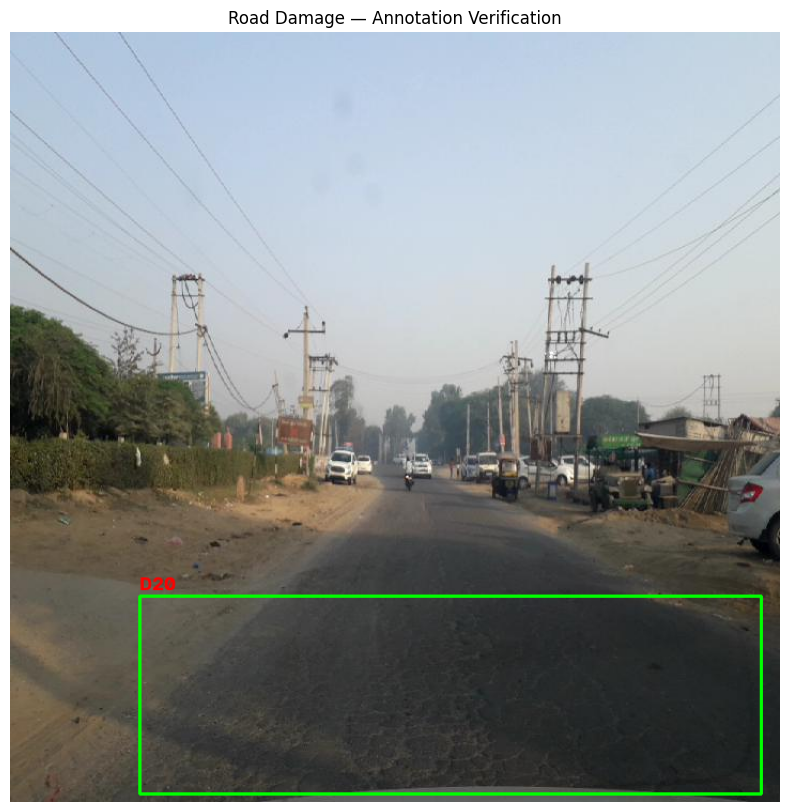

In [ ]:
import cv2
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pathlib import Path

# Change these paths to your actual dataset paths
IMAGE_PATH = Path("D:\\India\\train\\images\\India_000028.jpg")
XML_PATH = Path("D:\\India\\train\\annotations\\xmls\\India_000028.xml")

# Read image
image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

# Convert BGR to RGB for correct display
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Read XML
root = ET.parse(XML_PATH).getroot()

print("Image:", root.findtext("filename"))
print("XML dimensions:",
      root.findtext("size/width"),
      "x",
      root.findtext("size/height"))

# Draw bounding boxes
for obj in root.findall("object"):
    class_name = obj.findtext("name")
    box = obj.find("bndbox")

    if box is None:
        print("Missing bounding box:", class_name)
        continue

    xmin = int(float(box.findtext("xmin")))
    ymin = int(float(box.findtext("ymin")))
    xmax = int(float(box.findtext("xmax")))
    ymax = int(float(box.findtext("ymax")))

    # Draw rectangle
    cv2.rectangle(
        image,
        (xmin, ymin),
        (xmax, ymax),
        (0, 255, 0),
        2
    )

    # Add class name
    cv2.putText(
        image,
        class_name,
        (xmin, max(ymin - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

    print(
        f"Class: {class_name}, "
        f"Box: ({xmin}, {ymin}, {xmax}, {ymax})"
    )

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.title("Road Damage — Annotation Verification")
plt.axis("off")
plt.show()